In [6]:
import pathlib
import sys

import torch
import torch.optim as optim
from fsspec.config import conf

from torch import nn
from torch.cuda import device
from torch.utils.data import DataLoader
from pathlib import Path
from torch.optim.lr_scheduler import StepLR
from torch.utils.data import random_split
from loguru import logger

from scripts.train_with_checkpoint import MLFLOW_PATH
from src.config.config import Config
from neurostreak.trainer import TrainerNeuroStreak
from neurostreak.dataset import NeuroStreakDataset
from src.data import StreakImageDataset
import numpy as np
import ptwt
import matplotlib.pyplot as plt


In [7]:
name = 'exp.ipynb'
CURRENT_ROOT = Path(name).resolve()
PROJECT_ROOT = CURRENT_ROOT.parent.parent
CONFIG_PATH = PROJECT_ROOT /  Path('src/config/config.yaml')
CONFIG_TRAIN = PROJECT_ROOT /  Path('src/config/config_train.yaml')
DATASET_PATHS =[ PROJECT_ROOT / Path('data/clean_water_20m')]
MLFLOW_PATH = PROJECT_ROOT / 'mlruns' / 'models'

In [8]:
CONFIG_PATH

WindowsPath('C:/Users/supervisor.LTCPC-280426-01/PycharmProjects/NeuroStreak/src/config/config.yaml')

In [10]:
from mlflow.pytorch import load_model

MODEL_ID = 'm-2a462234f8024743a79c68c9a13bdf7b'

model = load_model(MLFLOW_PATH / MODEL_ID / 'artifacts')

In [11]:
print(model)

NeurostreakArch(
  (embedding): NeuroStreakEmbeddingGPU(
    (spectral_embedding_block): FDEmbeddingBlock(
      (flatten): Flatten(start_dim=1, end_dim=-1)
      (norm): LayerNorm((8000,), eps=1e-05, elementwise_affine=True)
      (dense): Linear(in_features=8000, out_features=512, bias=True)
      (act): SiLU()
    )
    (wavelet_amplitude_embedding_block): WaveletEmbeddingBlockGPU()
  )
  (backbone): NeuroStreakBackbone(
    (wavelet_attention_block): WaveletAttentionBlock(
      (convolution): Sequential(
        (0): Conv2d(1, 8, kernel_size=(1, 7), stride=(1, 3), padding=(0, 3))
        (1): ReLU(inplace=True)
        (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
        (3): Conv2d(8, 16, kernel_size=(1, 3), stride=(1, 2), padding=(0, 1))
        (4): ReLU(inplace=True)
        (5): MaxPool2d(kernel_size=(2, 1), stride=1, padding=0, dilation=1, ceil_mode=False)
      )
      (embedding_projection): Linear(in_features=1, out_features=1, bias=True

In [16]:
print(dir(model), sep=' ')

['T_destination', '__annotations__', '__call__', '__class__', '__delattr__', '__dict__', '__dir__', '__doc__', '__eq__', '__format__', '__ge__', '__getattr__', '__getattribute__', '__getstate__', '__gt__', '__hash__', '__init__', '__init_subclass__', '__le__', '__lt__', '__module__', '__ne__', '__new__', '__reduce__', '__reduce_ex__', '__repr__', '__setattr__', '__setstate__', '__sizeof__', '__str__', '__subclasshook__', '__weakref__', '_apply', '_backward_hooks', '_backward_pre_hooks', '_buffers', '_call_impl', '_compiled_call_impl', '_forward_hooks', '_forward_hooks_always_called', '_forward_hooks_with_kwargs', '_forward_pre_hooks', '_forward_pre_hooks_with_kwargs', '_get_backward_hooks', '_get_backward_pre_hooks', '_get_name', '_is_full_backward_hook', '_load_from_state_dict', '_load_state_dict_post_hooks', '_load_state_dict_pre_hooks', '_maybe_warn_non_full_backward_hook', '_modules', '_named_members', '_non_persistent_buffers_set', '_parameters', '_register_load_state_dict_pre_hoo

In [25]:
model._modules.keys()

dict_keys(['embedding', 'backbone', 'head'])

In [26]:
model.head._modules.keys()

dict_keys(['spectral_head', 'wavelet_head', 'classifier'])

In [28]:
model.head.spectral_head._modules

{'projector': Sequential(
   (0): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
   (1): Linear(in_features=64, out_features=128, bias=True)
   (2): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
 ),
 'layer_norm': LayerNorm((128,), eps=1e-05, elementwise_affine=True),
 'adaptive_pool': AdaptivePooling(
   (mask): Sequential(
     (0): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
     (1): Linear(in_features=128, out_features=128, bias=True)
     (2): ReLU()
     (3): Linear(in_features=128, out_features=64, bias=True)
     (4): ReLU()
     (5): Linear(in_features=64, out_features=1, bias=True)
   )
 )}

In [33]:
model.head.classifier[0]

Linear(in_features=256, out_features=128, bias=True)

In [35]:
print(dir(model.head.classifier[0]), sep='  ')

['T_destination', '__annotations__', '__call__', '__class__', '__constants__', '__delattr__', '__dict__', '__dir__', '__doc__', '__eq__', '__format__', '__ge__', '__getattr__', '__getattribute__', '__getstate__', '__gt__', '__hash__', '__init__', '__init_subclass__', '__le__', '__lt__', '__module__', '__ne__', '__new__', '__reduce__', '__reduce_ex__', '__repr__', '__setattr__', '__setstate__', '__sizeof__', '__str__', '__subclasshook__', '__weakref__', '_apply', '_backward_hooks', '_backward_pre_hooks', '_buffers', '_call_impl', '_compiled_call_impl', '_forward_hooks', '_forward_hooks_always_called', '_forward_hooks_with_kwargs', '_forward_pre_hooks', '_forward_pre_hooks_with_kwargs', '_get_backward_hooks', '_get_backward_pre_hooks', '_get_name', '_is_full_backward_hook', '_load_from_state_dict', '_load_state_dict_post_hooks', '_load_state_dict_pre_hooks', '_maybe_warn_non_full_backward_hook', '_modules', '_named_members', '_non_persistent_buffers_set', '_parameters', '_register_load_s

In [36]:
model.head.classifier[0].weight

Parameter containing:
tensor([[ 0.0468, -0.0792,  0.0117,  ..., -0.0403, -0.0080,  0.0151],
        [ 0.1038, -0.1005, -0.0346,  ..., -0.0125, -0.0344, -0.0098],
        [ 0.0551, -0.0879, -0.0880,  ..., -0.0406,  0.0605,  0.0381],
        ...,
        [ 0.0393, -0.1677,  0.0307,  ...,  0.0186,  0.0064,  0.0701],
        [-0.0064,  0.0106, -0.0398,  ...,  0.0225, -0.0559, -0.0297],
        [ 0.0225, -0.0237, -0.0609,  ...,  0.0515,  0.0455,  0.0651]],
       device='cuda:0', requires_grad=True)

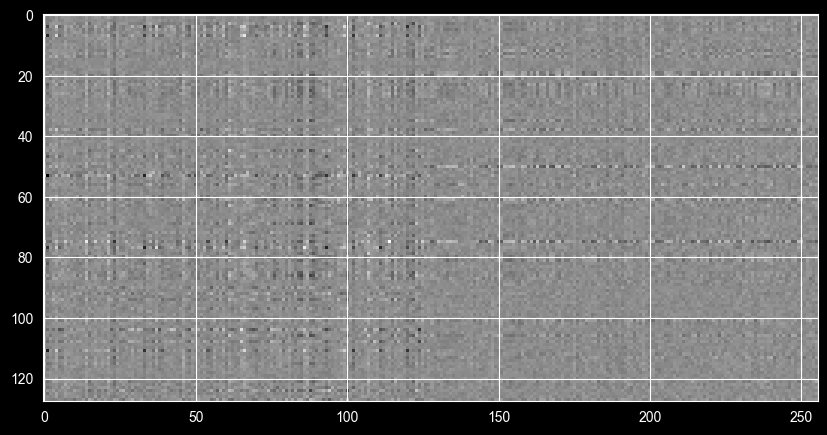

In [42]:
fig = plt.figure(figsize=(10, 10))
plt.imshow(model.head.classifier[0].weight.cpu().data.numpy(), cmap='gray')

In [45]:
model.backbone.wavelet_attention_block.convolution.modules

<bound method Module.modules of Sequential(
  (0): Conv2d(1, 8, kernel_size=(1, 7), stride=(1, 3), padding=(0, 3))
  (1): ReLU(inplace=True)
  (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (3): Conv2d(8, 16, kernel_size=(1, 3), stride=(1, 2), padding=(0, 1))
  (4): ReLU(inplace=True)
  (5): MaxPool2d(kernel_size=(2, 1), stride=1, padding=0, dilation=1, ceil_mode=False)
)>

In [48]:
for idx, layer in enumerate(model.backbone.wavelet_attention_block.convolution):
    if idx % 3 == 0:
        print(layer.weight.shape)

torch.Size([8, 1, 1, 7])
torch.Size([16, 8, 1, 3])


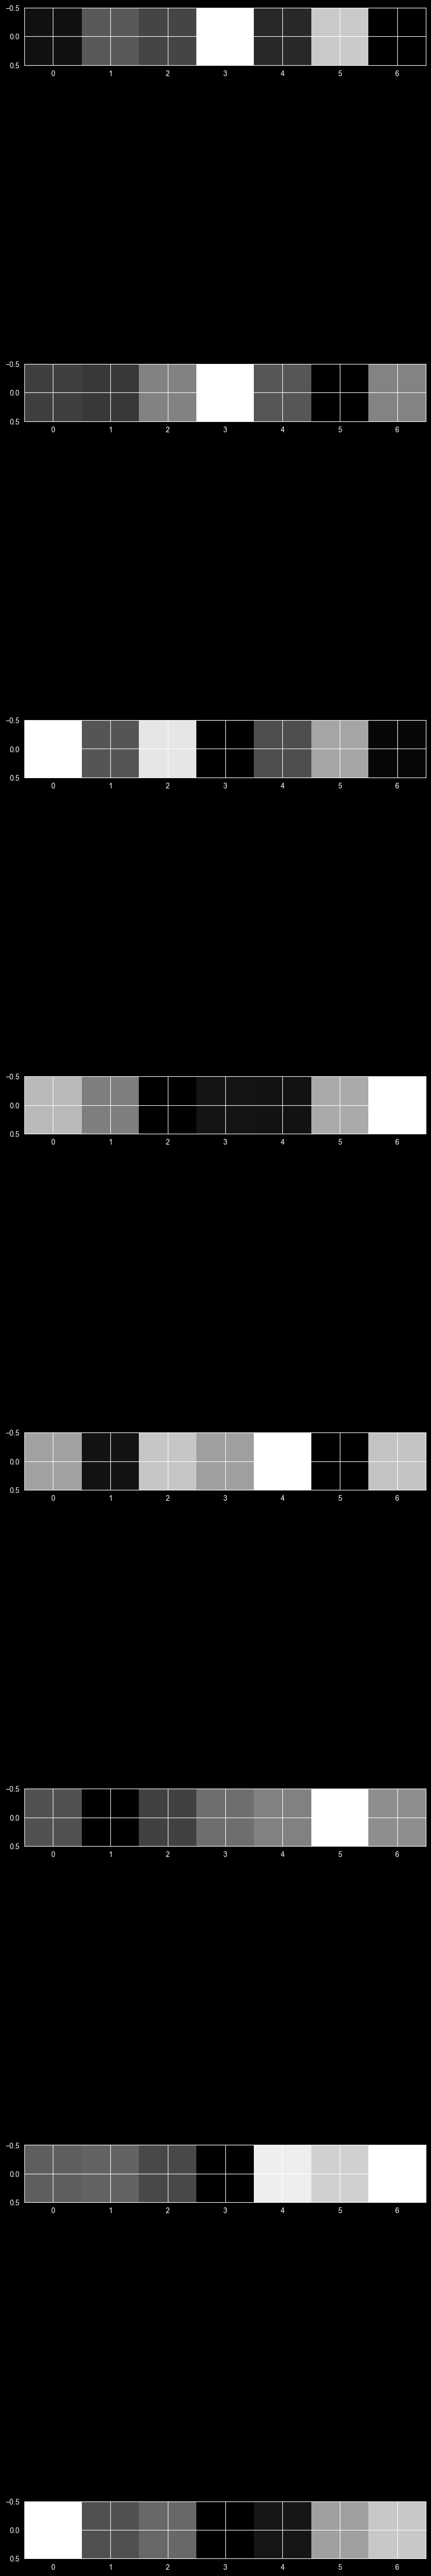

In [62]:
layer_1 = model.backbone.wavelet_attention_block.convolution[0]
layer_2 = model.backbone.wavelet_attention_block.convolution[3]

fig, ax = plt.subplots(8, 1, figsize=(10, 70))

for i in range(layer_1.weight.shape[0]):
    ax[i].imshow(layer_1.weight[i,0].cpu().data.numpy(), cmap='gray')